# Résultats des entraînements

Courbes tirées des `log.txt` des runs (format MimicKit, aussi écrit par `rl/train.py`, une ligne toutes les
50 itérations). On peut relancer le notebook à tout moment, y compris pendant un run : il ne fait que lire
les logs. Une section par run, puis les comparaisons. Chaque run enregistre ses figures dans son dossier
(`training_curves.png`, et `amp_curves.png` pour les runs AMP).

À lancer depuis la racine du repo, avec le kernel du venv du projet.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT = Path.cwd()
EP_STEPS = 600                                   # 20 s at 30 Hz

RUNS = {                                         # key -> (label, run dir); the order fixes the colors
    "run1_antoine": ("Run 1 Antoine (PPO MimicKit)", "outputs/phase3/ppo_heading"),
    "run1_roman": ("Run 1 Roman (PPO rl/)", "outputs/rl/ppo_heading"),
    "run2": ("Run 2 (AMP Walk)", "outputs/rl/amp_walk"),
    "run3": ("Run 3 (AMP Run)", "outputs/rl/amp_run"),
    "run4": ("Run 4 (AMP Locomotion)", "outputs/rl/amp_locomotion"),
}
COLORS = dict(zip(RUNS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))   # categorical, fixed order
PAIR = ["#2a78d6", "#eb6834"]                    # two series inside one run's figure
INK, GRID = "#3a3a38", "#e4e3df"


def read_log(path):
    """MimicKit's text log: a header line, then one row of values per output iteration."""
    tokens = Path(path).read_text().split()
    ncol = next(i for i, t in enumerate(tokens) if _is_number(t))
    header, values = tokens[:ncol], tokens[ncol:]
    nrow = len(values) // ncol
    data = np.array(values[:nrow * ncol], dtype=float).reshape(nrow, ncol)
    return {k: data[:, i] for i, k in enumerate(header)}


def _is_number(s):
    try:
        float(s)
        return True
    except ValueError:
        return False


def load(key):
    """Log of a run, or None (with a message) if it has no log.txt yet."""
    label, run_dir = RUNS[key]
    path = PROJECT / run_dir / "log.txt"
    if not path.exists():
        print(f"{label} : pas encore de log.txt")
        return None
    log = read_log(path)
    print(f"{label} : {len(log['Samples'])} lignes, {log['Samples'][-1] / 1e6:.0f} M échantillons, "
          f"{log['Wall_Time'][-1]:.2f} h, {log['Samples_Per_Second'][-1]:.0f} échantillons/s ; "
          f"dernier test : retour normalisé {log['Test_Return'][-1] / EP_STEPS:.3f}, "
          f"épisodes {log['Test_Episode_Length'][-1] / 30:.1f} s")
    return log


def style(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, color=INK)
    ax.set_ylabel(ylabel, color=INK)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=INK)


def plot_training(key, log):
    """Return and episode length, train (sampled actions) and test (mean action)."""
    label, run_dir = RUNS[key]
    s = log["Samples"] / 1e6
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for (prefix, name), color in zip([("Test", "test"), ("Train", "entraînement")], PAIR):
        axes[0].plot(s, log[f"{prefix}_Return"] / EP_STEPS, color=color, linewidth=2, label=name)
        axes[1].plot(s, log[f"{prefix}_Episode_Length"] / 30, color=color, linewidth=2, label=name)
    style(axes[0], "échantillons (M)", "retour de tâche normalisé")
    style(axes[1], "échantillons (M)", "durée des épisodes (s)")
    axes[0].set_ylim(0, 1)
    axes[1].set_ylim(0, 20.5)
    axes[0].legend(frameon=False, loc="lower right")
    fig.suptitle(label, color=INK)
    fig.tight_layout()
    fig.savefig(PROJECT / run_dir / "training_curves.png", dpi=110)
    plt.show()


def plot_amp(key, log):
    """Rewards and discriminator of an AMP run."""
    label, run_dir = RUNS[key]
    s = log["Samples"] / 1e6
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    panels = [
        (axes[0, 0], [("Task_Reward_Mean", "r_G (tâche)"), ("Style_Reward_Mean", "r_S (style)")],
         "récompense moyenne par pas", (0, 1)),
        (axes[0, 1], [("Disc_Acc_Mocap", "mocap jugée mocap"), ("Disc_Acc_Agent", "agent jugé agent")],
         "précision de D", (0, 1.02)),
        (axes[1, 0], [("Disc_Loss", "perte LSGAN (éq. 6)")], "perte de D", None),
        (axes[1, 1], [("Disc_Grad_Penalty", "pénalité de gradient (éq. 8)")], "pénalité de gradient", None),
    ]
    for ax, cols, ylabel, ylim in panels:
        for (col, name), color in zip(cols, PAIR):
            if col in log:
                ax.plot(s, log[col], color=color, linewidth=2, label=name)
        style(ax, "échantillons (M)", ylabel)
        if ylim:
            ax.set_ylim(*ylim)
        if len(cols) > 1:
            ax.legend(frameon=False)
        else:
            ax.set_title(cols[0][1], color=INK, fontsize=10)
    axes[0, 1].axhline(0.5, color="#8a8980", linewidth=1, linestyle="--")
    fig.suptitle(f"{label} : discriminateur", color=INK)
    fig.tight_layout()
    fig.savefig(PROJECT / run_dir / "amp_curves.png", dpi=110)
    plt.show()


def show_run(key):
    log = load(key)
    if log is None:
        return None
    plot_training(key, log)
    if "Disc_Acc_Mocap" in log:
        plot_amp(key, log)
    return log


logs = {}

## Run 1 Antoine : PPO de MimicKit

PPO seul (r_G), code de MimicKit (`amp/run.py`), `outputs/phase3/ppo_heading`.

Run 1 Antoine (PPO MimicKit) : 47 lignes, 300 M échantillons, 3.55 h, 23503 échantillons/s ; dernier test : retour normalisé 0.913, épisodes 19.6 s


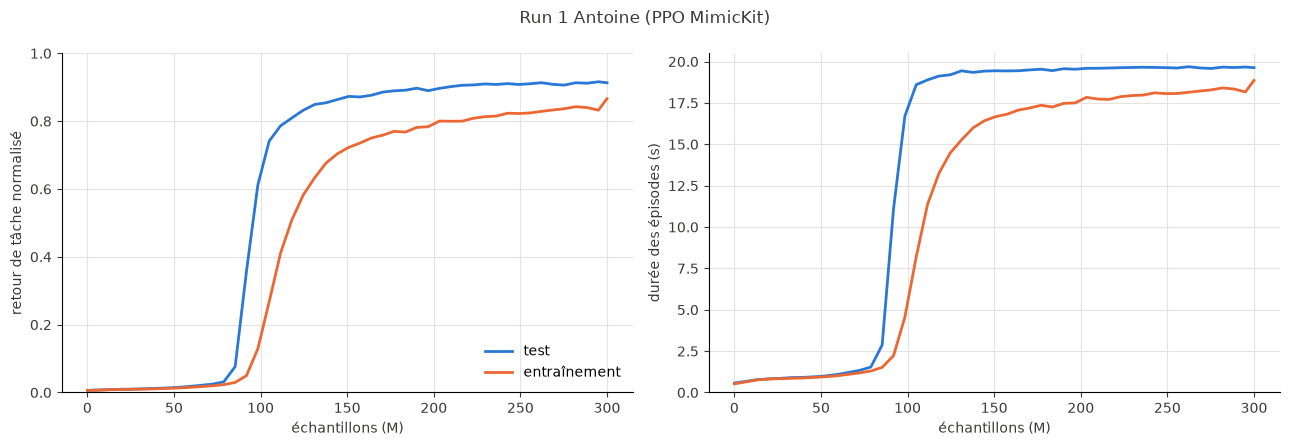

In [2]:
logs["run1_antoine"] = show_run("run1_antoine")

## Run 1 Roman : PPO de `rl/`

Même expérience avec notre PPO (`rl/train.py`), `outputs/rl/ppo_heading`.

Run 1 Roman (PPO rl/) : 47 lignes, 300 M échantillons, 3.73 h, 22365 échantillons/s ; dernier test : retour normalisé 0.918, épisodes 19.7 s


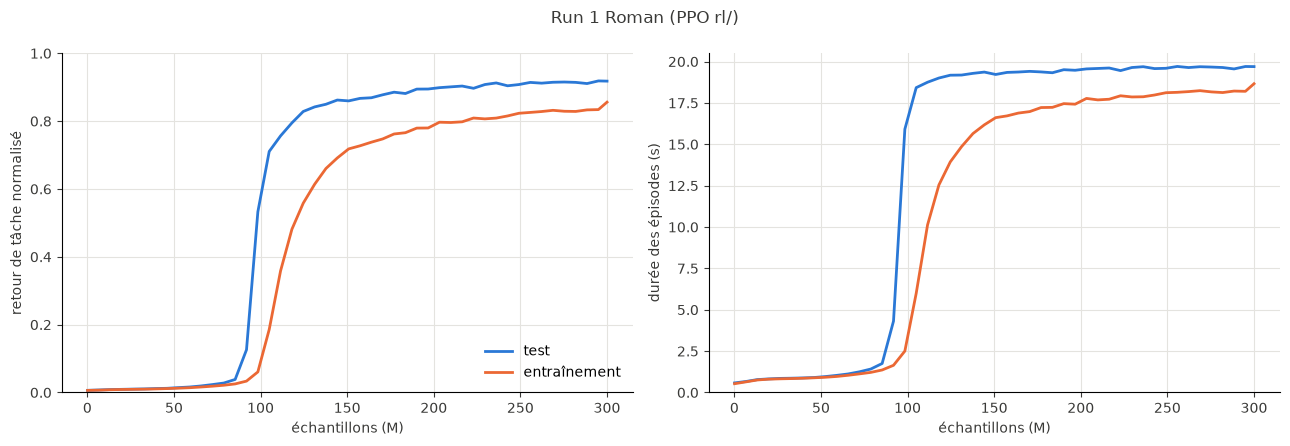

In [3]:
logs["run1_roman"] = show_run("run1_roman")

## Run 2 : AMP Walk

AMP de `rl/`, jeu de données Walk (9 clips), `outputs/rl/amp_walk`.

Repères AMP (`rl/README.md`) : précisions de D entre ~0,55 et ~0,95 (collées à 1 : D a gagné, r_S tombe à 0 ; collées à 0,5 : D n'apprend rien), r_S qui baisse au début puis remonte, pénalité de gradient petite et stable, r_G qui monte comme en PPO, sans doute plus lentement.

Run 2 (AMP Walk) : 47 lignes, 300 M échantillons, 4.77 h, 17488 échantillons/s ; dernier test : retour normalisé 0.818, épisodes 20.0 s


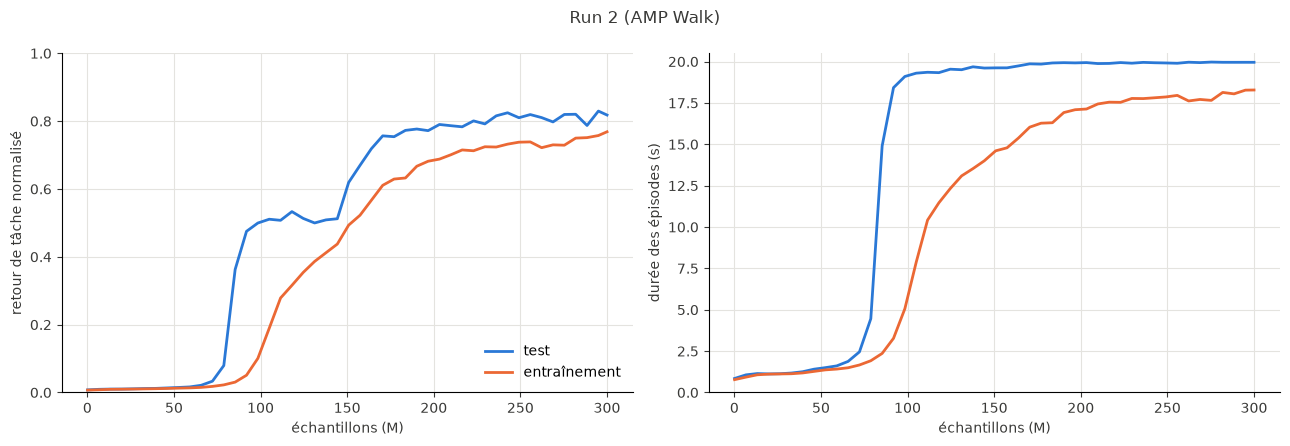

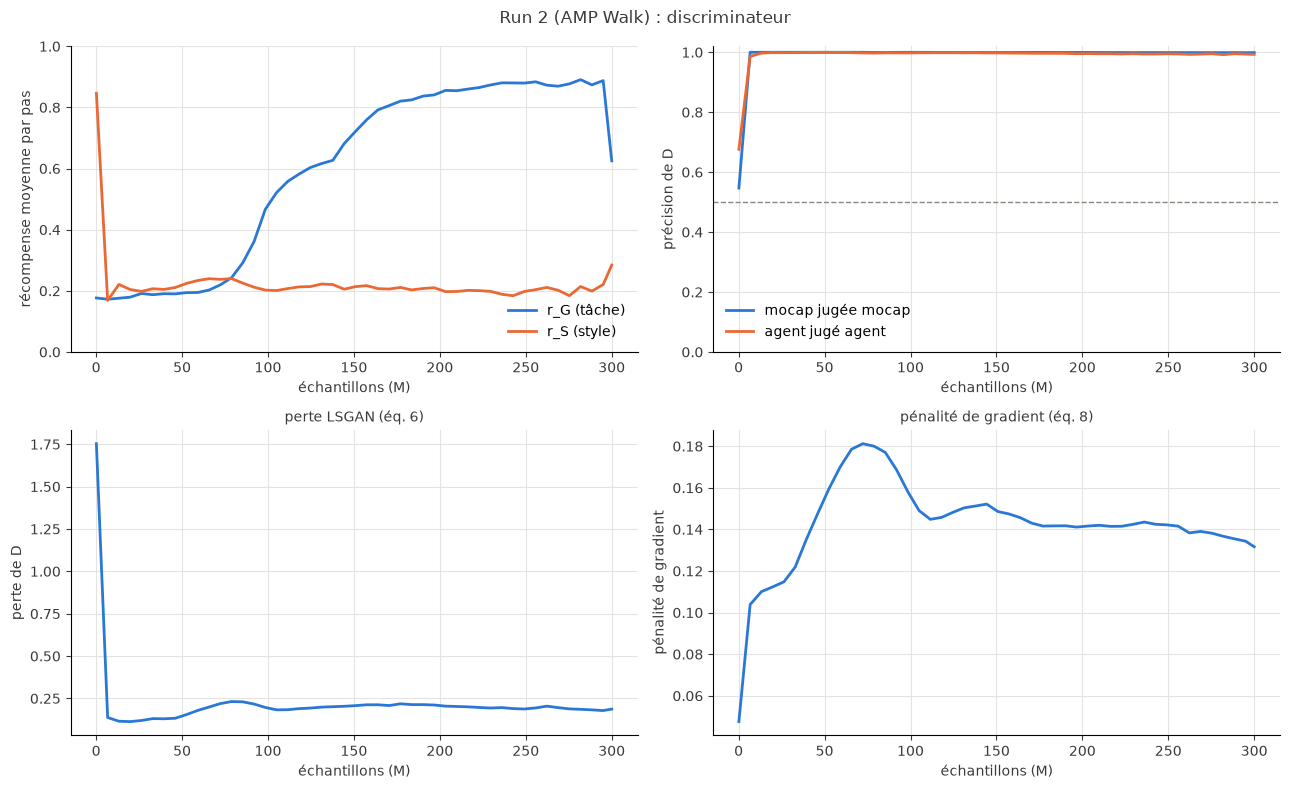

In [4]:
logs["run2"] = show_run("run2")

## Run 3 : AMP Run

AMP de `rl/`, jeu de données Run, `outputs/rl/amp_run`.

Run 3 (AMP Run) : 47 lignes, 300 M échantillons, 4.59 h, 18159 échantillons/s ; dernier test : retour normalisé 0.900, épisodes 19.6 s


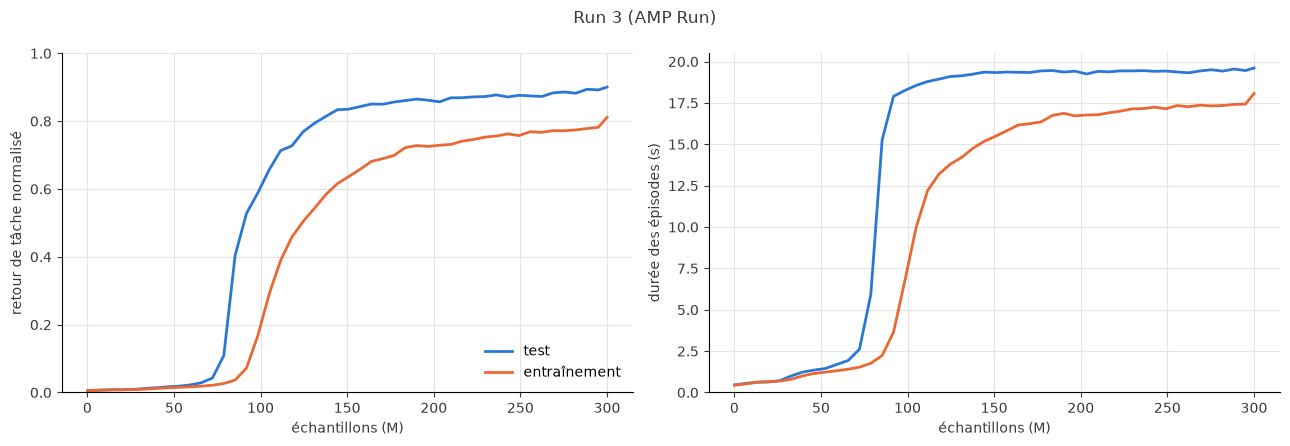

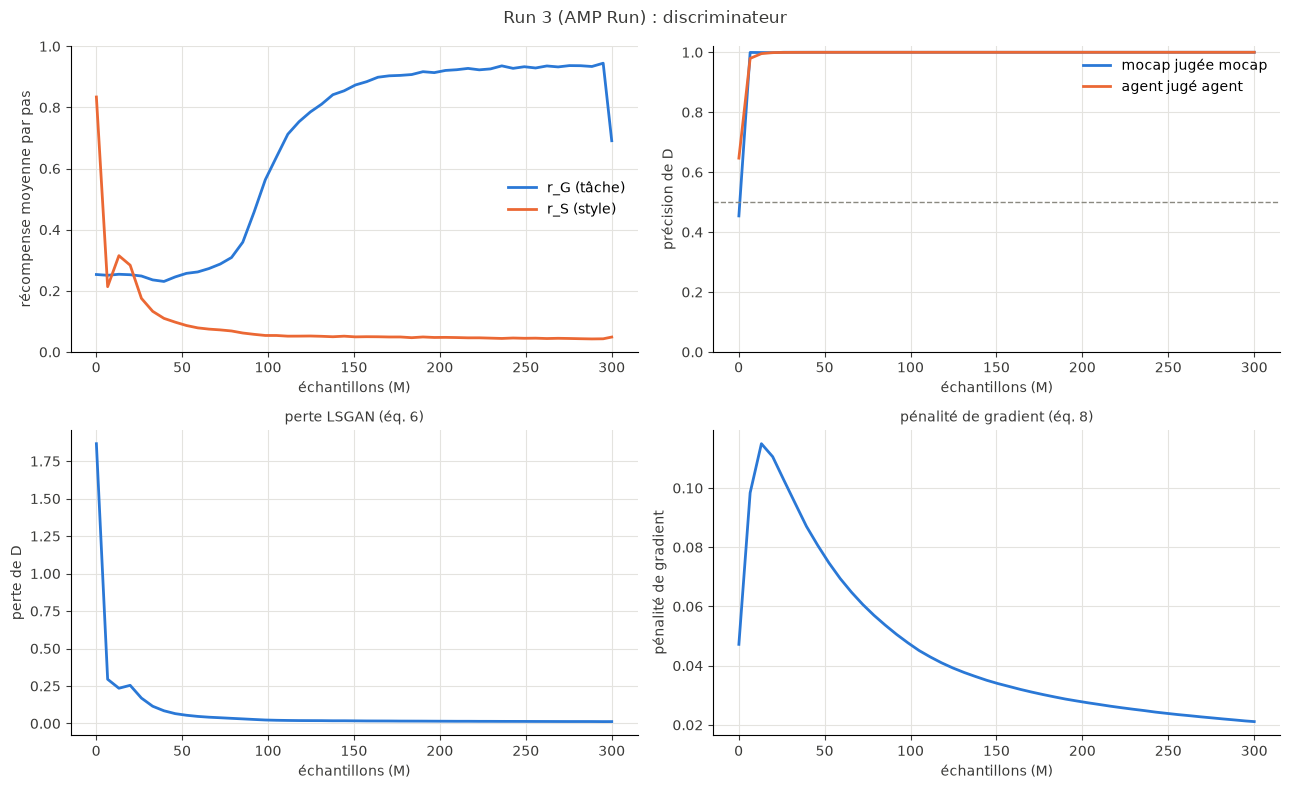

In [5]:
logs["run3"] = show_run("run3")

## Run 4 : AMP Locomotion

AMP de `rl/`, Walk + Run (56 clips), `outputs/rl/amp_locomotion`.

Run 4 (AMP Locomotion) : 47 lignes, 300 M échantillons, 4.45 h, 18738 échantillons/s ; dernier test : retour normalisé 0.873, épisodes 19.7 s


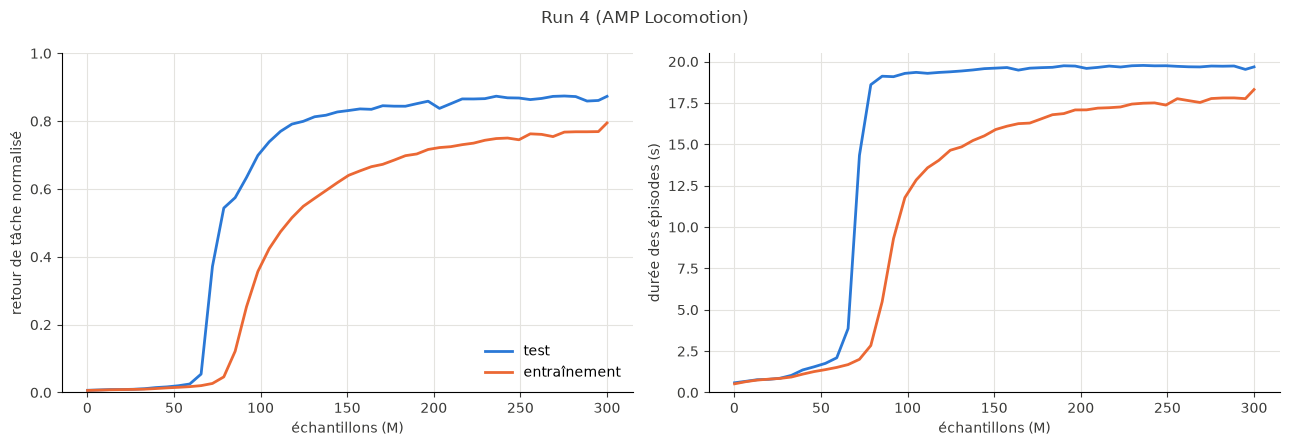

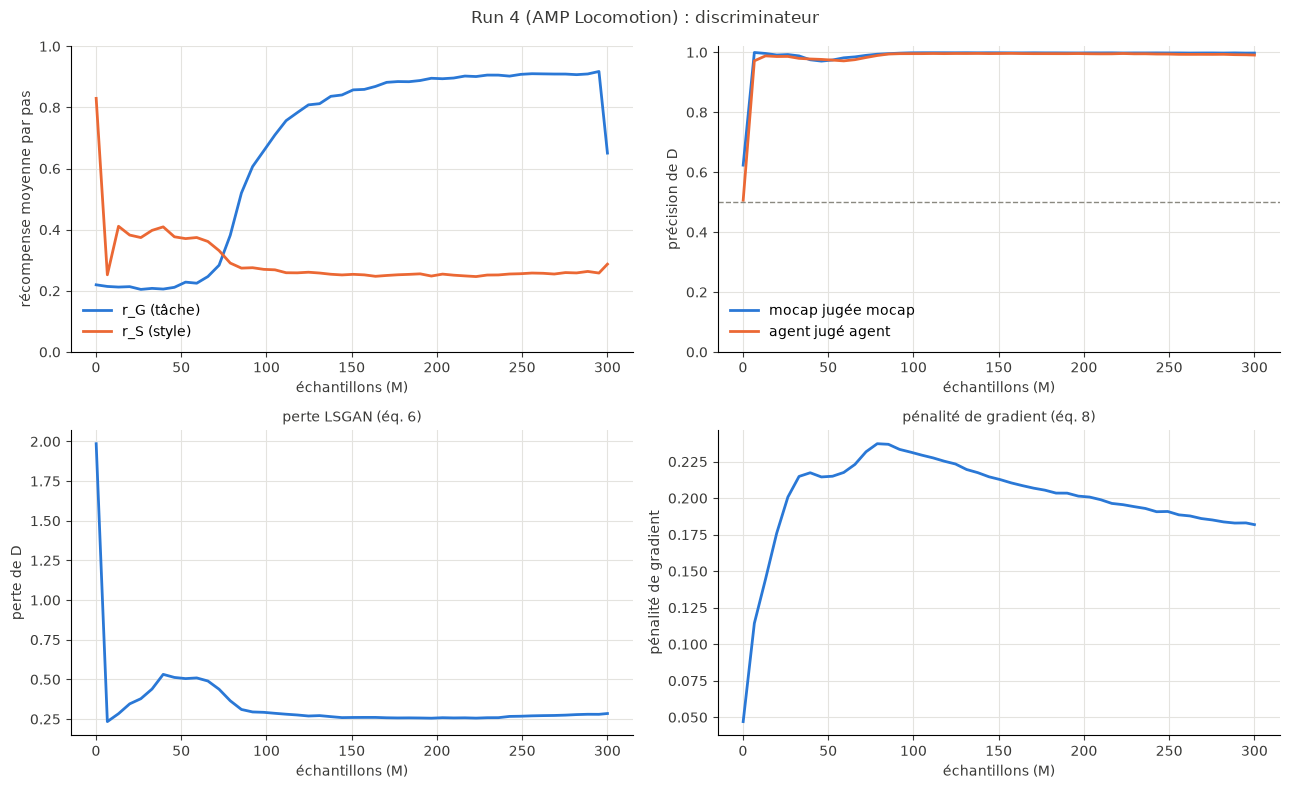

In [6]:
logs["run4"] = show_run("run4")

## Comparaison des runs : épisodes de test pendant l'entraînement

Retour de tâche normalisé = somme de r_G sur l'épisode / 600 (entre 0 et 1 ; pour les runs AMP, r_G seul,
donc comparable au PPO seul). Durée des épisodes : 20 s au maximum.

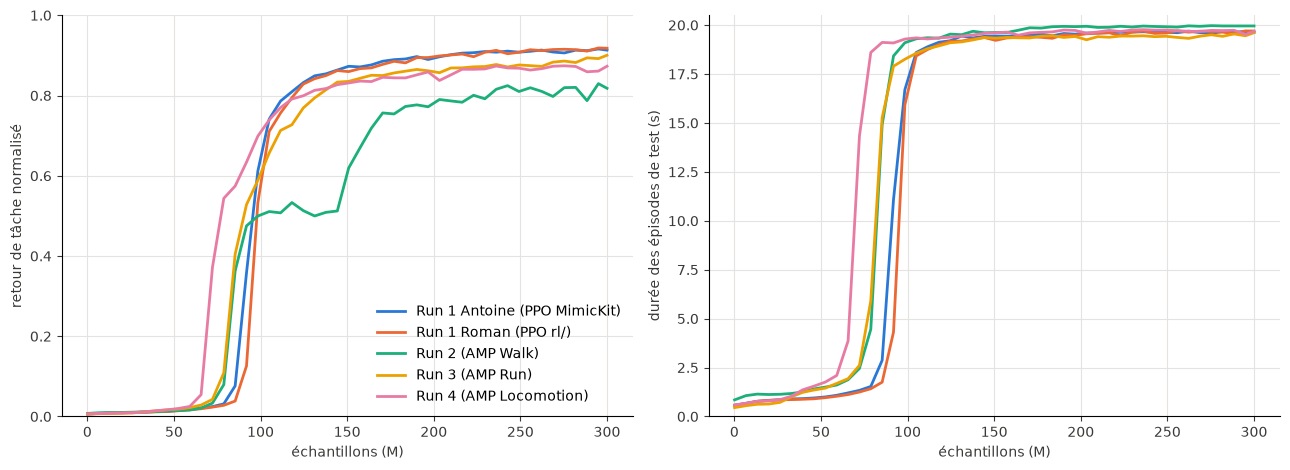

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for key, log in logs.items():
    if log is None:
        continue
    s = log["Samples"] / 1e6
    axes[0].plot(s, log["Test_Return"] / EP_STEPS, color=COLORS[key], linewidth=2, label=RUNS[key][0])
    axes[1].plot(s, log["Test_Episode_Length"] / 30, color=COLORS[key], linewidth=2, label=RUNS[key][0])
style(axes[0], "échantillons (M)", "retour de tâche normalisé")
style(axes[1], "échantillons (M)", "durée des épisodes de test (s)")
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 20.5)
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(PROJECT / "outputs" / "runs_comparison.png", dpi=110)
plt.show()

## Run 1 : PPO de MimicKit contre PPO de `rl/`

Même expérience : le décollage et le plateau doivent coïncider, au bruit près (une seule graine de chaque côté).

In [9]:
def first_crossing(log, col, value):
    """Samples (M) at the first log row where col >= value, or None."""
    idx = np.nonzero(log[col] >= value)[0]
    return log["Samples"][idx[0]] / 1e6 if len(idx) else None

for key in ("run1_antoine", "run1_roman"):
    label, log = RUNS[key][0], logs.get(key)
    if log is None:
        print(f"{label:30s} pas encore de log")
        continue
    t10 = first_crossing(log, "Test_Episode_Length", 10 * 30)
    last = slice(-5, None)                     # mean of the last 5 rows (~30 M samples)
    print(f"{label:30s} épisodes > 10 s à {'%.0f M' % t10 if t10 else 'pas encore'}, "
          f"fin : retour {log['Test_Return'][last].mean() / EP_STEPS:.3f}, "
          f"épisodes {log['Test_Episode_Length'][last].mean() / 30:.1f} s, "
          f"{log['Samples_Per_Second'][-1]:.0f} échantillons/s")

Run 1 Antoine (PPO MimicKit)   épisodes > 10 s à 92 M, fin : retour 0.912, épisodes 19.6 s, 23503 échantillons/s
Run 1 Roman (PPO rl/)          épisodes > 10 s à 98 M, fin : retour 0.915, épisodes 19.7 s, 22365 échantillons/s
